# Stellar Spectra

https://www.eso.org/sci/facilities/paranal/decommissioned/isaac/tools/lib.html

## Exercise 1

We are using for this one **ukg5iii.dat

In [22]:
import numpy as np

data = np.loadtxt('ukg5iii.dat')

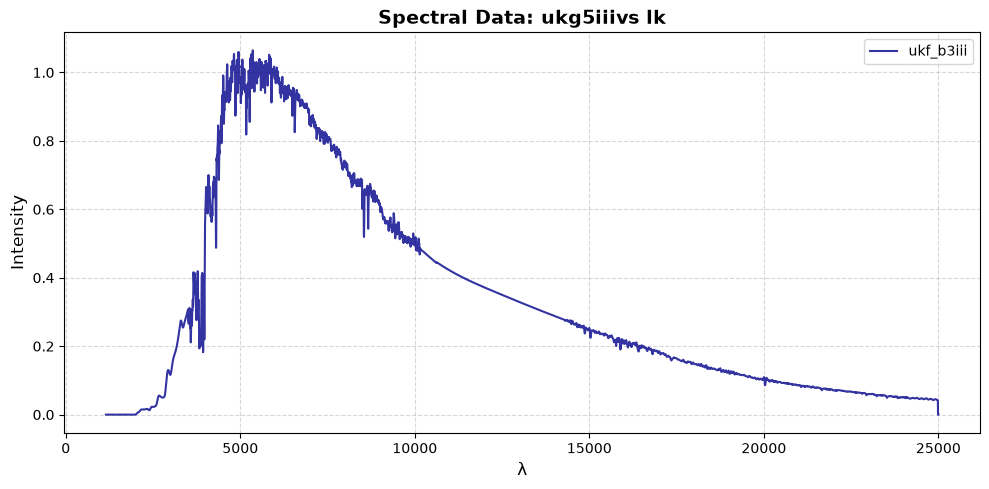

In [57]:
import matplotlib.pyplot as plt

x, y = np.loadtxt("ukg5iii.dat", comments="#", usecols=(0, 1), unpack=True)

plt.figure(figsize=(10, 5))
plt.plot(x, y, linestyle="-", color="darkblue", alpha=0.8, label="ukg5iii")

plt.title("Spectral Data: ukg5iiivs lk", fontsize=14, fontweight="bold")
plt.xlabel("λ", fontsize=12)
plt.ylabel("Intensity", fontsize=12)

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()

plt.show()


#### This we have to fit to the Black Body 

The equation of Black body is:  

$${\displaystyle B_{\lambda }(\lambda ,T)={\frac {2hc^{2}}{\lambda ^{5}}}{\frac {1}{\exp \left({\frac {hc}{\lambda k_{\mathrm {B} }T}}\right)-1}}}$$

Keep the values consistent, and also the exponential has to be dimentionless. Also, be careful with the units. 

Queremos ajustar:

$I_\lambda=A\,B_\lambda(\lambda,T)$

* T: temperatura que determina la forma de la curva.
* A: constante que ajusta su altura.
* Initial guess: una temperatura aproximada para comenzar el ajuste.

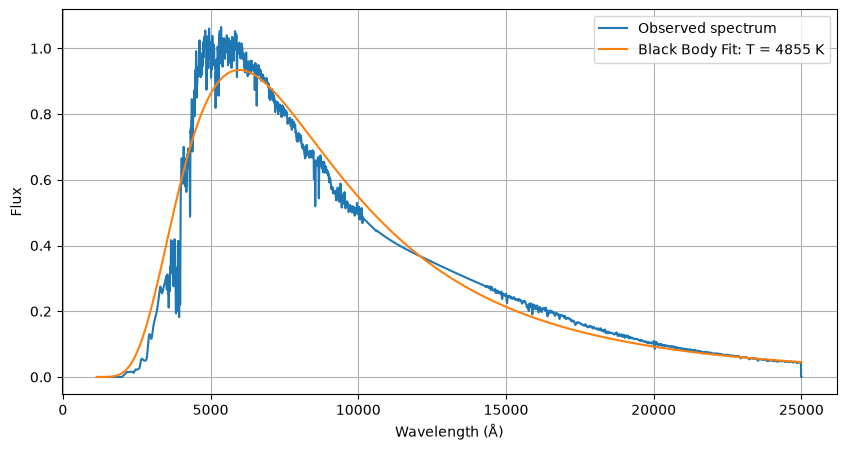

Temperature = 4855 K


In [52]:
from scipy.constants import h, c, k
from scipy.optimize import curve_fit

# Planck function
def planck(lam, T):
    lam = lam * 1e-10  
    return (2*h*c**2 / lam**5) / (np.exp(h*c / (lam*k*T)) - 1)

# Black body model
def blackbody(lam, T, A):
    return A * planck(lam, T)

# Initial guess
T0 = 18000
A0 = np.max(y) / np.max(planck(x, T0)) 

# Fit
params, covariance = curve_fit(
    blackbody, x, y,
    p0=[T0, A0],
    bounds=([1000, 0], [100000, np.inf]),
    maxfev=20000
)

T_fit, A_fit = params

# Plot
plt.figure(figsize=(10, 5))
plt.plot(x, y, label="Observed spectrum")
plt.plot(x, blackbody(x, T_fit, A_fit),
         label=f"Black Body Fit: T = {T_fit:.0f} K")

plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.legend()
plt.grid()
plt.show()

print(f"Temperature = {T_fit:.0f} K")

**FWHM of Hydrogen Lines as a Function of Temperature**

From the notes of class, we use that the FWHM

$$
\mathrm{FWHM} = \frac{2\lambda_0}{c}\sqrt{\frac{2k_BT\ln 2}{m}}
$$

where:
- $\lambda_0$: central wavelength of the spectral line.
- $k_B$: Boltzmann constant.
- $T$: temperature.
- $m$: mass of hydrogen.

We calculate the FWHM for three lines:

- H$\alpha$: 6562.8 Å
- H$\beta$: 4861.3 Å
- H$\gamma$: 4340.5 Å

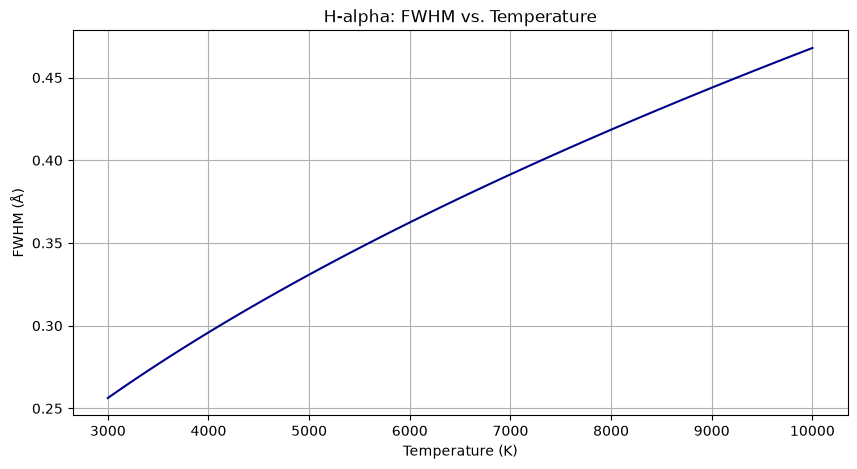

In [43]:
# 1. H-alpha Wavelength

lam0 = 6562.8  # Angstroms
T = np.linspace(3000, 10000, 100)

k = 1.380649e-23 # Boltzmann constant 
c = 3e8      
m_H = 1.6735575e-27 # Mass of hydrogen


def fwhm_doppler(lam0, T):
    lam0 = lam0 * 1e-10
    fwhm = (2 * lam0 / c) * np.sqrt(2 * k * T * np.log(2) / m_H)
    return fwhm * 1e10


plt.figure(figsize=(10, 5))
plt.plot(T, fwhm_doppler(lam0, T), color="darkblue")

plt.xlabel("Temperature (K)")
plt.ylabel("FWHM (Å)")
plt.title("H-alpha: FWHM vs. Temperature")
plt.grid(True)
plt.show()

The curve increases with temeperature so its following the T.

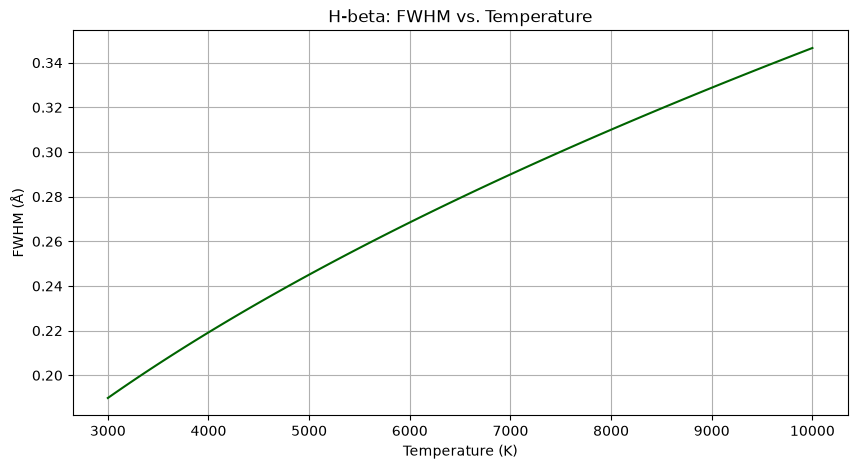

In [44]:
# H beta Wavelength
lam0 = 4861.3  # Angstroms
T = np.linspace(3000, 10000, 100)


FWHM_beta = fwhm_doppler(lam0, T)


plt.figure(figsize=(10, 5))
plt.plot(T, FWHM_beta, color="darkgreen")

plt.xlabel("Temperature (K)")
plt.ylabel("FWHM (Å)")
plt.title("H-beta: FWHM vs. Temperature")
plt.grid(True)
plt.show()

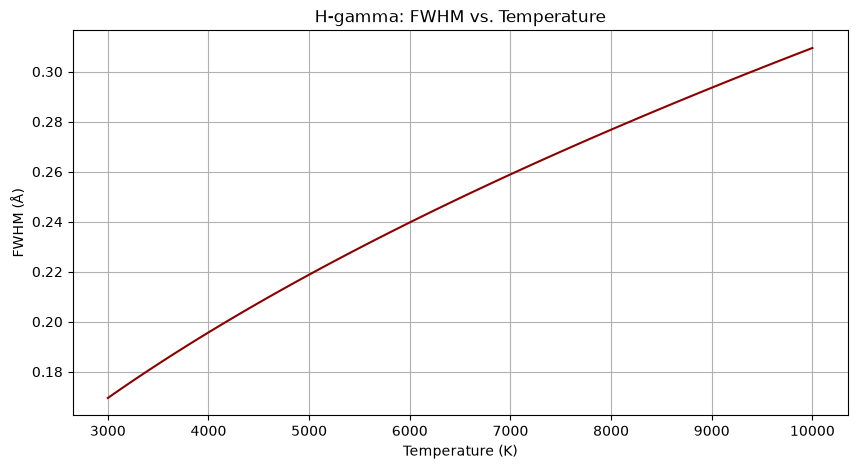

In [45]:
lam0 = 4340.5  # Angstroms

T = np.linspace(3000, 10000, 100)

FWHM_gamma = fwhm_doppler(lam0, T)

plt.figure(figsize=(10, 5))
plt.plot(T, FWHM_gamma, color="darkred")

plt.xlabel("Temperature (K)")
plt.ylabel("FWHM (Å)")
plt.title("H-gamma: FWHM vs. Temperature")
plt.grid(True)
plt.show()

In [46]:
# FWHM Results

print(f"H-alpha: {fwhm_doppler(6562.8, 3000):.4f} - {fwhm_doppler(6562.8, 10000):.4f} Å")
print(f"H-beta:  {fwhm_doppler(4861.3, 3000):.4f} - {fwhm_doppler(4861.3, 10000):.4f} Å")
print(f"H-gamma: {fwhm_doppler(4340.5, 3000):.4f} - {fwhm_doppler(4340.5, 10000):.4f} Å")

H-alpha: 0.2563 - 0.4679 Å
H-beta:  0.1898 - 0.3466 Å
H-gamma: 0.1695 - 0.3095 Å


**Lorentzian profile**

It describes the spectral broadening, including natural broadening. 

From our notes we have that, 
$$
L(x)=\frac{1}{\pi\gamma_L}
\frac{\gamma_L^2}{x^2+\gamma_L^2}
$$

where $x$ is the distance from the line center and $\gamma_L$ is the half-width at half maximum.

$$
\mathrm{FWHM}=2\gamma_L
$$

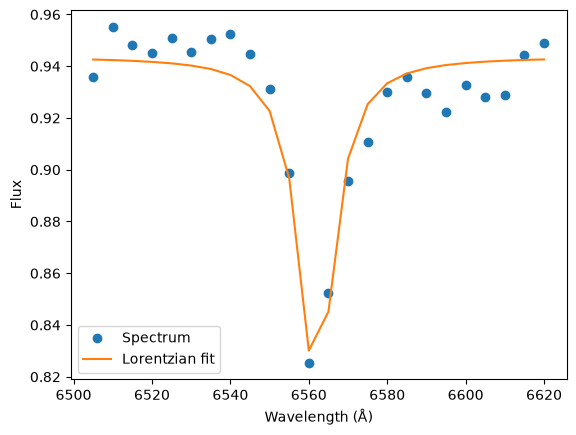

FWHM = 10.5297 Å


In [49]:
# Lorentzian Profile equation 
def lorentz(lam, C, A, lam0, gamma):
    return C - A * gamma**2 / ((lam - lam0)**2 + gamma**2)

# We have a range
mask = (x > 6500) & (x < 6625)
lam = x[mask]
flux = y[mask]

# Fit: compare the lorentzian function with the observed data and find the best parameters 
params, _ = curve_fit(lorentz, lam, flux,
                      p0=[max(flux), max(flux)-min(flux), 6562.8, 10])


plt.plot(lam, flux, "o", label="Spectrum")
plt.plot(lam, lorentz(lam, *params), label="Lorentzian fit")
plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.legend()
plt.show()

print(f"FWHM = {2*abs(params[3]):.4f} Å")

The result we got means that the H-alpha absorption line has a fitted width of approximately 10.53 Å at HFWM. 

## Exercise 2
We are using for this exercise the Specrtal type B and the roman number III

**file name:** ukb3iii.dat


In [54]:
import numpy as np

data = np.loadtxt('ukb3iii.dat')

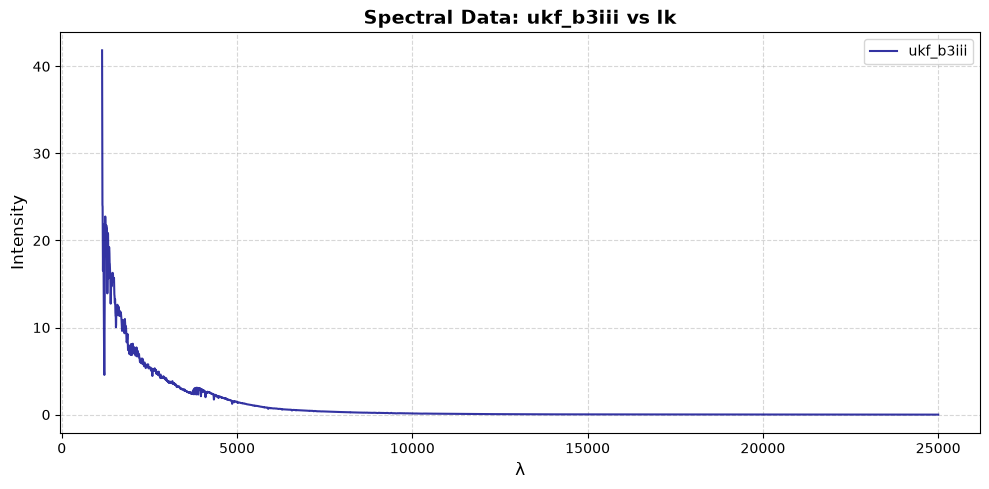

In [55]:
import matplotlib.pyplot as plt

x, y = np.loadtxt("ukb3iii.dat", comments="#", usecols=(0, 1), unpack=True)

plt.figure(figsize=(10, 5))
plt.plot(x, y, linestyle="-", color="darkblue", alpha=0.8, label="ukf_b3iii")


plt.title("Spectral Data: ukf_b3iii vs lk", fontsize=14, fontweight="bold")
plt.xlabel("λ", fontsize=12)
plt.ylabel("Intensity", fontsize=12)


plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()

plt.show()


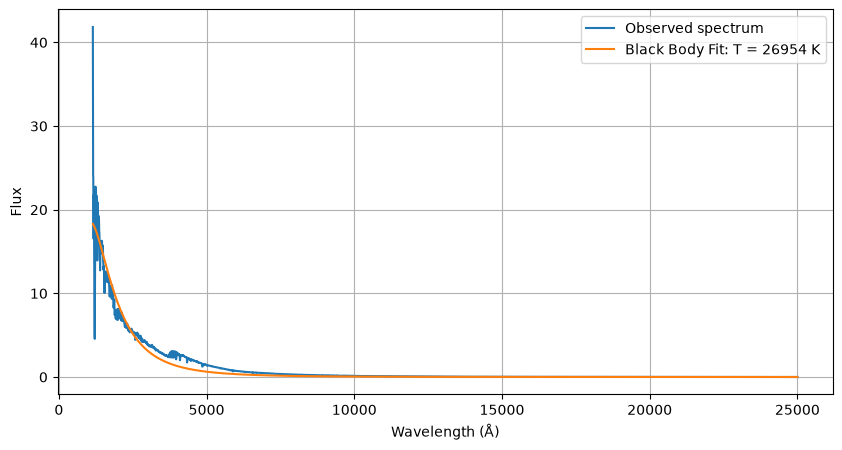

Temperature = 26954 K


In [56]:
from scipy.constants import h, c, k
from scipy.optimize import curve_fit

#Planck Function
def planck(lam, T):
    lam = lam * 1e-10
    return (2*h*c**2 / lam**5) / (np.exp(h*c / (lam*k*T)) - 1)

# Black Body Model
def blackbody(lam, T, A):
    return A * planck(lam, T)

# Initial Guesses
T0 = 18000
A0 = np.max(y) / np.max(planck(x, T0))

# Black Body Fitting
params, covariance = curve_fit(
    blackbody, x, y,
    p0=[T0, A0],
    bounds=([1000, 0], [100000, np.inf]),
    maxfev=20000
)

T_fit, A_fit = params

# Plot Observed Spectrum and Black Body Fit
plt.figure(figsize=(10, 5))
plt.plot(x, y, label="Observed spectrum")
plt.plot(x, blackbody(x, T_fit, A_fit),
         label=f"Black Body Fit: T = {T_fit:.0f} K")

plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.legend()
plt.grid()
plt.show()

# Best-Fit Temperature
print(f"Temperature = {T_fit:.0f} K")

# Personal Notes 

1. Blackbody Fit

* We fitted Planck’s law to the stellar spectrum.
* The temperature determines the overall shape of the spectrum.

2. FWHM vs. Temperature

* We calculated the thermal Doppler broadening of Hα, Hβ, and Hγ.
* Higher temperatures mean faster-moving atoms and wider spectral lines.
* The FWHM increases as ($\sqrt{T}$).
* These are theoretical values, not measurements from the spectrum.

3. Lorentzian Fit

* We fitted a Lorentzian profile to the observed Hα absorption line.
* The Lorentzian describes natural and collisional broadening.
* This is the width of the fitted absorption line, not natural broadening alone.

Conclusion: We estimated the star’s temperature, studied how temperature affects hydrogen line widths, and fitted the observed Hα line using a Lorentzian profile.

# Code explained

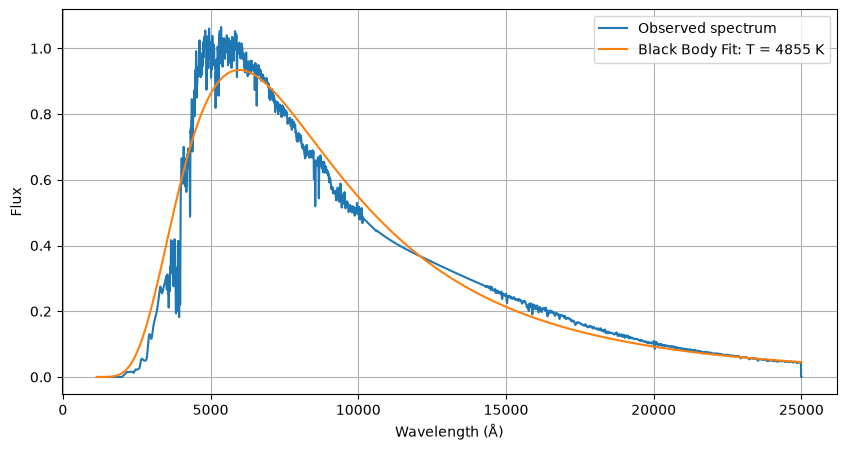

Temperature = 4855 K


In [25]:
from scipy.constants import h, c, k
from scipy.optimize import curve_fit

# 1. Planck function
# Calculates the spectral radiance of a black body at a given wavelength and temperature.
def planck(lam, T):
    # Convert wavelength from Angstroms to meters (SI units).
    lam = lam * 1e-10

    # Apply Planck's law.
    # np.expm1(x) is equivalent to exp(x) - 1, but more numerically accurate.
    return (2*h*c**2 / lam**5) / np.expm1(h*c / (lam*k*T))


# 2. Black body model
# Multiply Planck's function by a scaling constant A.
# A adjusts the amplitude of the curve to match the observed spectrum.
def blackbody(lam, T, A):
    return A * planck(lam, T)


# 3. Initial guesses
# Provide starting values for the fitting algorithm.
T0 = 18000  # Initial temperature guess in Kelvin (K).

# Estimate the initial scaling constant by comparing the maximum observed
# intensity with the maximum intensity predicted by Planck's function.
A0 = np.max(y) / np.max(planck(x, T0))


# 4. Fit the black body model to the observed spectrum
# curve_fit finds the values of T and A that minimize the squared
# differences between the observed data and the theoretical model.
params, covariance = curve_fit(
    blackbody, x, y,
    p0=[T0, A0],                         # Initial guesses for T and A.
    bounds=([1000, 0], [100000, np.inf]), # Allowed parameter ranges.
    maxfev=20000                        # Maximum number of function evaluations.
)

# Extract the best-fit temperature and scaling constant.
T_fit, A_fit = params


# 5. Plot the results
plt.figure(figsize=(10, 5))

# Plot the observed spectrum.
plt.plot(x, y, label="Observed spectrum")

# Plot the theoretical black body curve using the fitted parameters.
plt.plot(x, blackbody(x, T_fit, A_fit),
         label=f"Black Body Fit: T = {T_fit:.0f} K")

# Add labels, legend, and grid.
plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.legend()
plt.grid()
plt.show()


# 6. Display the fitted temperature
print(f"Temperature = {T_fit:.0f} K")